Utilizando a base de dados Titanic ('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'), responda às seguintes perguntas:

In [298]:
#Importar as Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# 1) Analisar os dados: verificar os tipos de variáveis, verificar dados ausentes, e visualizar estatísticas descritivas.

In [299]:
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'

df_titanic = pd.read_csv(url)

In [300]:
df_titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [301]:
df_titanic.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [302]:
df_titanic.shape
# 891 linhas e 12 colunas

(891, 12)

In [303]:
df_titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**Dicionário de Dados — Titanic**

| Variável | Descrição | Tipo | Mensuração | Valores |
| :--- | :--- | :--- | :--- | :--- |
| **`PassengerId`** | Número de identificação único do passageiro | Numérico | Discreta | Inteiro de 1 a 891 |
| **`Survived`** | Indica se o passageiro sobreviveu ao naufrágio | Categórico | Nominal | **0** = Não<br>**1** = Sim |
| **`Pclass`** | Classe do bilhete (indicador socioeconômico) | Categórico | Ordinal | **1** = 1ª Classe (Alta)<br>**2** = 2ª Classe (Média)<br>**3** = 3ª Classe (Baixa) |
| **`Name`** | Nome completo do passageiro | Categórico | Nominal | Texto |
| **`Sex`** | Gênero do passageiro | Categórico | Nominal | `male`, `female` |
| **`Age`** | Idade do passageiro em anos | Numérico | Contínua | Valor racional (ex: 22, 0.92) |
| **`SibSp`** | Número de irmãos e cônjuges a bordo | Numérico | Discreta | Inteiro (0, 1, 2, ...) |
| **`Parch`** | Número de pais e filhos a bordo | Numérico | Discreta | Inteiro (0, 1, 2, ...) |
| **`Ticket`** | Número da passagem / bilhete | Categórico | Nominal | Texto / Alfanumérico |
| **`Fare`** | Tarifa paga pelo bilhete | Numérico | Contínua | Valor decimal/monetário |
| **`Cabin`** | Número do camarote / cabine | Categórico | Nominal | Texto (contém valores nulos) |
| **`Embarked`** | Porto onde o passageiro embarcou | Categórico | Nominal | **C** = Cherbourg<br>**Q** = Queenstown<br>**S** = Southampton |

In [304]:
df_titanic.duplicated().sum()
# nenhuma linha duplicada

np.int64(0)

In [305]:
df_titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [306]:
df_titanic['Age'].unique()
# essa coluna é do tipo float porque existem passageiros que são bebês recém-nascidos (idade menor que 1 ano)

array([22.  , 38.  , 26.  , 35.  ,   nan, 54.  ,  2.  , 27.  , 14.  ,
        4.  , 58.  , 20.  , 39.  , 55.  , 31.  , 34.  , 15.  , 28.  ,
        8.  , 19.  , 40.  , 66.  , 42.  , 21.  , 18.  ,  3.  ,  7.  ,
       49.  , 29.  , 65.  , 28.5 ,  5.  , 11.  , 45.  , 17.  , 32.  ,
       16.  , 25.  ,  0.83, 30.  , 33.  , 23.  , 24.  , 46.  , 59.  ,
       71.  , 37.  , 47.  , 14.5 , 70.5 , 32.5 , 12.  ,  9.  , 36.5 ,
       51.  , 55.5 , 40.5 , 44.  ,  1.  , 61.  , 56.  , 50.  , 36.  ,
       45.5 , 20.5 , 62.  , 41.  , 52.  , 63.  , 23.5 ,  0.92, 43.  ,
       60.  , 10.  , 64.  , 13.  , 48.  ,  0.75, 53.  , 57.  , 80.  ,
       70.  , 24.5 ,  6.  ,  0.67, 30.5 ,  0.42, 34.5 , 74.  ])

In [307]:
df_titanic.loc[df_titanic['Age'] < 1]
# essas são as linhas onde a idade do passageiro é menor que 1.

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
78,79,1,2,"Caldwell, Master. Alden Gates",male,0.83,0,2,248738,29.0000,NaN,S
305,306,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S
469,470,1,3,"Baclini, Miss. Helene Barbara",female,0.75,2,1,2666,19.2583,NaN,C
644,645,1,3,"Baclini, Miss. Eugenie",female,0.75,2,1,2666,19.2583,NaN,C
755,756,1,2,"Hamalainen, Master. Viljo",male,0.67,1,1,250649,14.5000,NaN,S
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C
831,832,1,2,"Richards, Master. George Sibley",male,0.83,1,1,29106,18.7500,NaN,S


In [308]:
df_titanic.groupby(['Pclass', 'Sex'])['Age'].transform('median')
# O transform devolve a mediana do grupo de cada passageiro, alinhada linha a linha, então cada nulo recebe a mediana da sua combinação de classe e sexo.
# vou usar isso para preencher as idades nulas no item 5

,Age
0,25.0
1,35.0
2,21.5
3,35.0
4,25.0
...,...
886,30.0
887,35.0
888,21.5
889,40.0


In [309]:
df_titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [310]:
df_titanic[['Age', 'SibSp', 'Parch', 'Fare']].describe()
# visualizando estatísticas descritivas (excluindo variáveis categóricas representadas por numeros)

,Age,SibSp,Parch,Fare
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,0.523008,0.381594,32.204208
std,14.526497,1.102743,0.806057,49.693429
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,0.000000,0.000000,7.910400
50%,28.000000,0.000000,0.000000,14.454200
75%,38.000000,1.000000,0.000000,31.000000
max,80.000000,8.000000,6.000000,512.329200


In [311]:
df_titanic[['Survived', 'Pclass']].mode()
# a classe que mais apareceu foi a terceira

,Survived,Pclass
0,0,3


# 2) Agrupar os dados para responder a perguntas relevantes, como a média da idade dos passageiros por classe e por sexo.

In [312]:
# estatísticas descritivas da idade dos passageiros por classe
df_titanic.groupby('Pclass')[['Age']].agg(['mean', 'median', 'min', 'max'])

Age                   
             mean median   min   max
Pclass                              
1       38.233441   37.0  0.92  80.0
2       29.877630   29.0  0.67  70.0
3       25.140620   24.0  0.42  74.0

In [313]:
# estatísticas descritivas da idade dos passageiros por sexo
df_titanic.groupby('Sex')[['Age']].agg(['mean', 'median', 'min', 'max'])

Age                   
             mean median   min   max
Sex                                 
female  27.915709   27.0  0.75  63.0
male    30.726645   29.0  0.42  80.0

In [314]:
# média da idade dos passageiros por classe e sexo juntos
df_titanic.groupby(['Pclass', 'Sex'])[['Age']].mean().unstack()

# na 1ª classe, homens têm em média 41 anos e mulheres 35

Age           
Sex        female       male
Pclass                      
1       34.611765  41.281386
2       28.722973  30.740707
3       21.750000  26.507589

In [315]:
# estatísticas descritivas da Tarifa (Fare) dos passageiros por classe
df_titanic.groupby('Pclass')[['Fare']].agg(['mean', 'median', 'min', 'max'])

# interessante de perceber aqui é que a classe que teve a maior tarifa máxima foi a primeira classe.

Fare                        
             mean   median  min       max
Pclass                                   
1       84.154687  60.2875  0.0  512.3292
2       20.662183  14.2500  0.0   73.5000
3       13.675550   8.0500  0.0   69.5500

In [316]:
# estatísticas descritivas da Tarifa (Fare) dos passageiros por sexo
df_titanic.groupby('Sex')[['Fare']].agg(['mean', 'median', 'min', 'max'])

Fare                       
             mean median   min       max
Sex                                     
female  44.479818   23.0  6.75  512.3292
male    25.523893   10.5  0.00  512.3292

In [317]:
zero_fare = df_titanic.loc[df_titanic['Fare'] == 0]
zero_fare

# são 15 passageiros com tarifa zero, e só 4 deles têm o ticket LINE.
# todos os passageiros que pagaram tarifa zero são homens

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
179,180,0,3,"Leonard, Mr. Lionel",male,36.0,0,0,LINE,0.0,NaN,S
263,264,0,1,"Harrison, Mr. William",male,40.0,0,0,112059,0.0,B94,S
271,272,1,3,"Tornquist, Mr. William Henry",male,25.0,0,0,LINE,0.0,NaN,S
277,278,0,2,"Parkes, Mr. Francis ""Frank""",male,NaN,0,0,239853,0.0,NaN,S
302,303,0,3,"Johnson, Mr. William Cahoone Jr",male,19.0,0,0,LINE,0.0,NaN,S
413,414,0,2,"Cunningham, Mr. Alfred Fleming",male,NaN,0,0,239853,0.0,NaN,S
466,467,0,2,"Campbell, Mr. William",male,NaN,0,0,239853,0.0,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0,NaN,S
597,598,0,3,"Johnson, Mr. Alfred",male,49.0,0,0,LINE,0.0,NaN,S
633,634,0,1,"Parr, Mr. William Henry Marsh",male,NaN,0,0,112052,0.0,NaN,S


In [318]:
# estatísticas descritivas da tarifa de embarque agrupadas pela classe e pelo sexo

df_titanic.groupby(['Pclass', 'Sex'])[['Fare']].agg(['mean', 'median', 'min', 'max'])
# as mulheres tiveram média e mediana de tarifa maior que a dos homens em todas as classes

Fare                             
                     mean    median      min       max
Pclass Sex                                            
1      female  106.125798  82.66455  25.9292  512.3292
       male     67.226127  41.26250   0.0000  512.3292
2      female   21.970121  22.00000  10.5000   65.0000
       male     19.741782  13.00000   0.0000   73.5000
3      female   16.118810  12.47500   6.7500   69.5500
       male     12.661633   7.92500   0.0000   69.5500

In [319]:
# estatísticas descritivas da tarifa agrupadas pela classe e pelo ponto de embarque

df_titanic.groupby(['Pclass', 'Embarked'])[['Fare']].agg(['mean', 'median', 'min', 'max'])
# a média da tarifa no ponto de embarque Cherbourg foi a maior em todas as classes
# a mediana da tarifa de quem embarcou em Cherbourg foi a maior apenas na segunda e terceira classes

Fare                            
                       mean   median      min       max
Pclass Embarked                                        
1      C         104.718529  78.2667  26.5500  512.3292
       Q          90.000000  90.0000  90.0000   90.0000
       S          70.364862  52.0000   0.0000  263.0000
2      C          25.358335  24.0000  12.0000   41.5792
       Q          12.350000  12.3500  12.3500   12.3500
       S          20.327439  13.5000   0.0000   73.5000
3      C          11.214083   7.8958   4.0125   22.3583
       Q          11.183393   7.7500   6.7500   29.1250
       S          14.644083   8.0500   0.0000   69.5500

In [320]:
filt = (df_titanic['Embarked'] == 'Q') & (df_titanic['Pclass'] == 1)
df_titanic.loc[filt]

# a média dos passageiros da primeira classe e que embarcaram em Queenstown foi exatamente 90 por isso!

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
245,246,0,1,"Minahan, Dr. William Edward",male,44.0,2,0,19928,90.0,C78,Q
412,413,1,1,"Minahan, Miss. Daisy E",female,33.0,1,0,19928,90.0,C78,Q


# 3) Utilizar matplotlib e seaborn para criar gráficos que representem os dados agrupados.

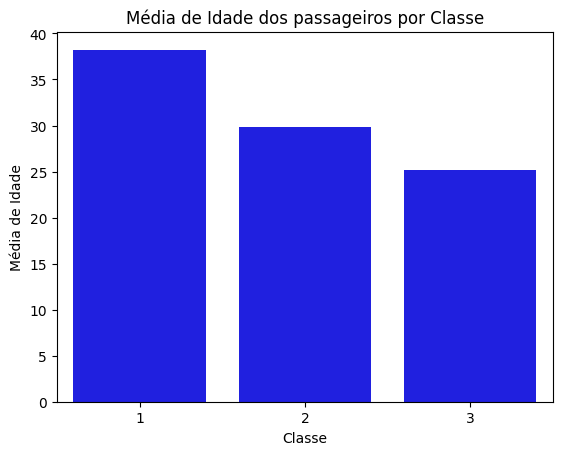

In [321]:
age_statistics_by_class = df_titanic.groupby('Pclass')['Age'].agg(['mean', 'median', 'min', 'max'])

sns.barplot(x=age_statistics_by_class.index, y=age_statistics_by_class['mean'], color='blue')
plt.xlabel('Classe')
plt.ylabel('Média de Idade')
plt.title('Média de Idade dos passageiros por Classe')
plt.show()

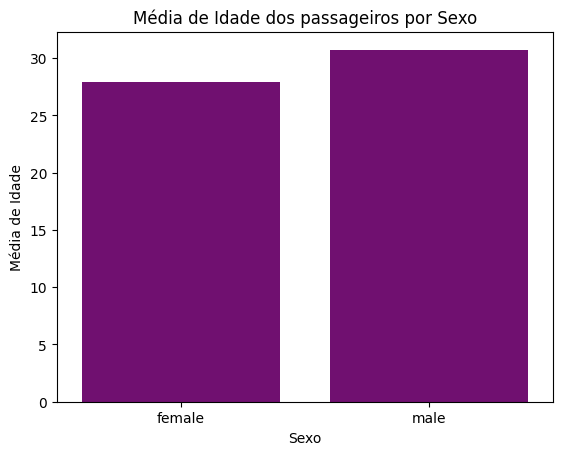

In [322]:
age_statistics_by_sex = df_titanic.groupby('Sex')[['Age']].mean()

sns.barplot(x=age_statistics_by_sex.index, y=age_statistics_by_sex['Age'], color='purple')
plt.xlabel('Sexo')
plt.ylabel('Média de Idade')
plt.title('Média de Idade dos passageiros por Sexo')
plt.show()

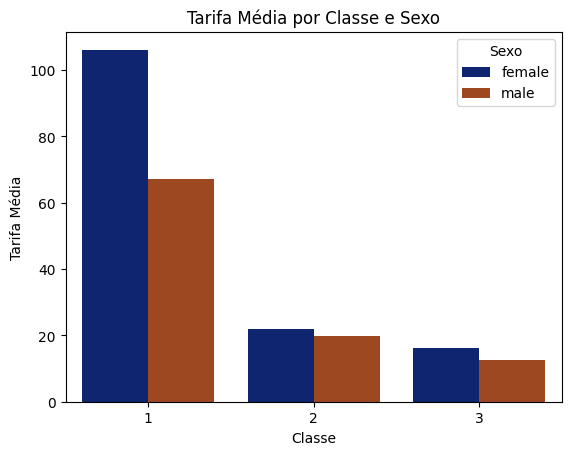

In [323]:
# mean_fare_by_class_and_sex = df_titanic.groupby(['Pclass', 'Sex'])['Fare'].mean()
# não precisa calcular o groupby antes de plotar; o barplot calcula a média por categoria.

sns.barplot(data=df_titanic, x='Pclass', y='Fare', hue='Sex', errorbar=None, palette='dark')
plt.xlabel('Classe')
plt.ylabel('Tarifa Média')
plt.legend(title='Sexo')
plt.title('Tarifa Média por Classe e Sexo')
plt.show()

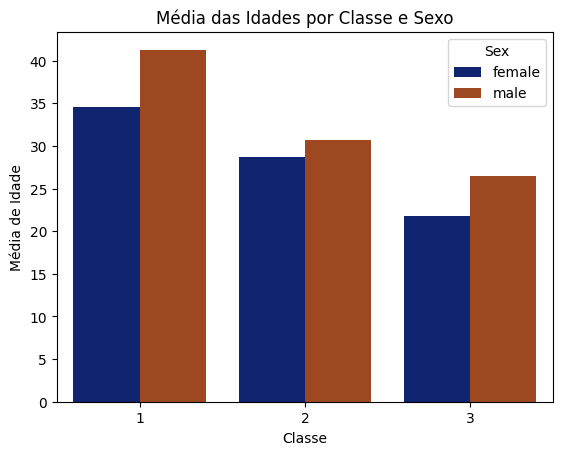

In [324]:
# idade por classe e sexo juntos
sns.barplot(data=df_titanic, x='Pclass', y='Age', hue='Sex', errorbar=None, palette='dark')
plt.xlabel('Classe')
plt.ylabel('Média de Idade')
plt.title('Média das Idades por Classe e Sexo')
plt.show()

# os passageiros com a maior média de idade (mais velhos) embarcaram na primeira classe.
# em todas as classes, os homens são em média mais velhos que as mulheres

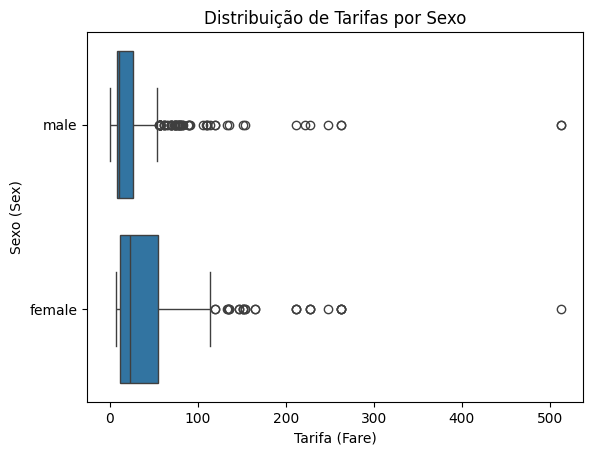

In [325]:
# Criando o boxplot da tarifa agrupada por sexo usando o Seaborn
sns.boxplot(data=df_titanic, x='Fare', y='Sex', orient='h')

plt.xlabel('Tarifa (Fare)')
plt.ylabel('Sexo (Sex)')
plt.title('Distribuição de Tarifas por Sexo')
plt.show()

# mulheres tiveram tarifas maiores: a mediana das tarifas das mulheres foi maior que a dos homens.

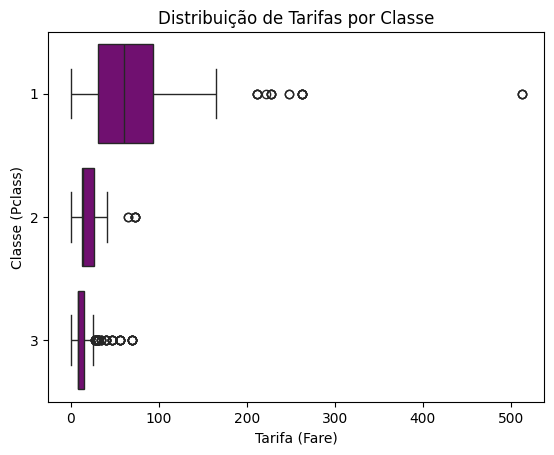

In [326]:
# Criando o boxplot da tarifa agrupada por Classe usando o Seaborn
sns.boxplot(data=df_titanic, x='Fare', y='Pclass', orient='h', color='purple')

plt.xlabel('Tarifa (Fare)')
plt.ylabel('Classe (Pclass)')
plt.title('Distribuição de Tarifas por Classe')
plt.show()

#4) Agrupar e visualizar a taxa de sobrevivência por classe.

# 5) Identificar e tratar valores ausentes.
   Transformar variáveis categóricas em numéricas (ex.: usar pd.get_dummies).
   Selecionar as características e o rótulo para a modelagem.

In [327]:
# Calcula a porcentagem de valores nulos por coluna
nulos_percentual = (df_titanic.isna().sum() / len(df_titanic)) * 100

# Filtra apenas as colunas que possuem valores ausentes e as ordena
nulos_percentual = nulos_percentual[nulos_percentual > 0].sort_values(ascending=False)
colunas_com_nulos = (df_titanic.isna().sum() > 0).sum()
print(f'Total de colunas com valores nulos: {colunas_com_nulos}')

print("\nPorcentagem de dados ausentes por coluna:")
print(nulos_percentual)

Total de colunas com valores nulos: 3

Porcentagem de dados ausentes por coluna:
Cabin       77.104377
Age         19.865320
Embarked     0.224467
dtype: float64


In [328]:
df_titanic['Age'] = df_titanic['Age'].fillna(
    df_titanic.groupby(['Pclass', 'Sex'])['Age'].transform('median')
)

# O transform devolve a mediana do grupo de cada passageiro, alinhada linha a linha, então cada nulo recebe a mediana da sua combinação de classe e sexo.

In [329]:
# 77% dos valores na coluna 'Cabin' estão ausentes, por isso vou removê-la
df_titanic = df_titanic.drop(columns='Cabin')
df_titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [330]:
df_titanic['Embarked'] = df_titanic['Embarked'].fillna(value=df_titanic['Embarked'].mode()[0])

df_titanic.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


# 6) Dividir o conjunto em treino e teste.

# 7) Importar e treinar o modelo de árvore de decisão.
   Visualizar a árvore de decisão -> procure estratégias para melhorar a visualização da árvore

# 8) Realizar previsões no conjunto de teste.
Calcular e interpretar as métricas de desempenho: acurácia, matriz de confusão, e relatório de classificação.

# 9) Analisar a importância das características utilizadas na árvore de decisão.